# 02 - LoRA from scratch

In [1]:
from pathlib import Path

import torch

BASE_MODEL = "Qwen/Qwen3.5-0.8B-Base"
DATA_ROOT = Path("data").resolve()
DEVICE = "cuda"
torch.manual_seed(0)

## Model

In [2]:
from transformers import AutoModelForImageTextToText, AutoProcessor

processor = AutoProcessor.from_pretrained(BASE_MODEL)
processor.tokenizer.padding_side = "right"

processor.chat_template = processor.tokenizer.chat_template
model = AutoModelForImageTextToText.from_pretrained(BASE_MODEL, dtype=torch.bfloat16).to(DEVICE)
model.requires_grad_(False)

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Qwen3_5ForConditionalGeneration(
  (model): Qwen3_5Model(
    (visual): Qwen3_5VisionModel(
      (patch_embed): Qwen3_5VisionPatchEmbed(
        (proj): Conv3d(3, 768, kernel_size=(2, 16, 16), stride=(2, 16, 16))
      )
      (pos_embed): Embedding(2304, 768)
      (rotary_pos_emb): Qwen3_5VisionRotaryEmbedding()
      (blocks): ModuleList(
        (0-11): 12 x Qwen3_5VisionBlock(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attn): Qwen3_5VisionAttention(
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (mlp): Qwen3_5VisionMLP(
            (linear_fc1): Linear(in_features=768, out_features=3072, bias=True)
            (linear_fc2): Linear(in_features=3072, out_features=768, bias=True)
            (act_fn): GELUTanh()
          )
        )
      )
      (mer

In [3]:
print("vision encoder:")
print(model.model.visual)

vision encoder:
Qwen3_5VisionModel(
  (patch_embed): Qwen3_5VisionPatchEmbed(
    (proj): Conv3d(3, 768, kernel_size=(2, 16, 16), stride=(2, 16, 16))
  )
  (pos_embed): Embedding(2304, 768)
  (rotary_pos_emb): Qwen3_5VisionRotaryEmbedding()
  (blocks): ModuleList(
    (0-11): 12 x Qwen3_5VisionBlock(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Qwen3_5VisionAttention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (proj): Linear(in_features=768, out_features=768, bias=True)
      )
      (mlp): Qwen3_5VisionMLP(
        (linear_fc1): Linear(in_features=768, out_features=3072, bias=True)
        (linear_fc2): Linear(in_features=3072, out_features=768, bias=True)
        (act_fn): GELUTanh()
      )
    )
  )
  (merger): Qwen3_5VisionPatchMerger(
    (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
    (linear_fc1): Linear(in_features=3072,

In [4]:
print("language model:")
print(model.model.language_model)

language model:
Qwen3_5TextModel(
  (embed_tokens): Embedding(248320, 1024)
  (layers): ModuleList(
    (0-2): 3 x Qwen3_5DecoderLayer(
      (linear_attn): Qwen3_5GatedDeltaNet(
        (act): SiLUActivation()
        (conv1d): Conv1d(6144, 6144, kernel_size=(4,), stride=(1,), padding=(3,), groups=6144, bias=False)
        (norm): FusedRMSNormGated(128, eps=1e-06, activation=silu)
        (out_proj): Linear(in_features=2048, out_features=1024, bias=False)
        (in_proj_qkv): Linear(in_features=1024, out_features=6144, bias=False)
        (in_proj_z): Linear(in_features=1024, out_features=2048, bias=False)
        (in_proj_b): Linear(in_features=1024, out_features=16, bias=False)
        (in_proj_a): Linear(in_features=1024, out_features=16, bias=False)
      )
      (mlp): Qwen3_5MLP(
        (gate_proj): Linear(in_features=1024, out_features=3584, bias=False)
        (up_proj): Linear(in_features=1024, out_features=3584, bias=False)
        (down_proj): Linear(in_features=3584, ou

In [5]:
print("output layer")
print(model.lm_head)

output layer
Linear(in_features=1024, out_features=248320, bias=False)


## Data

In [6]:
import json
import random

from huggingface_hub import hf_hub_download

index = hf_hub_download("EdisonScientific/glyph-datasets", "markush/train.jsonl", repo_type="dataset")
records = [r for r in map(json.loads, open(index)) if r["source"] == "molparser"]
random.Random(0).shuffle(records)
val_records, train_records = records[:200], records[200:]

In [7]:
from PIL import Image


def prompt_text(user_text):
    messages = [{
        "role": "user",
        "content": [
            {"type": "image"},
            {
                "type": "text",
                "text": user_text
            }
        ]
    }]
    return processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)


def collate(batch):
    """Tokenize image + prompt + target; the loss is computed only on target tokens."""
    images, texts, prompt_lens = [], [], []
    for r in batch:
        user_text = r["messages"][0]["content"].replace("<image>\n", "")
        target = r["messages"][1]["content"]
        image = Image.open(DATA_ROOT / r["images"][0]).convert("RGB")
        prompt = prompt_text(user_text)
        images.append(image)
        texts.append(prompt + target + "<|im_end|>")
        prompt_lens.append(processor(text=[prompt], images=[image], return_tensors="pt")["input_ids"].shape[1])
    inputs = processor(text=texts, images=images, padding=True, return_tensors="pt")
    labels = inputs["input_ids"].clone()
    labels[inputs["attention_mask"] == 0] = -100
    for i, n in enumerate(prompt_lens):
        labels[i, :n] = -100
    inputs["labels"] = labels
    return inputs

## Loss

In [8]:
import torch.nn.functional as F


def compute_loss(batch):
    """Computing the loss only on target tokens to avoid OOM."""
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    labels = batch.pop("labels")
    hidden = model.model(**batch).last_hidden_state

    hidden, labels = hidden[:, :-1], labels[:, 1:]
    mask = labels != -100
    
    logits = model.lm_head(hidden[mask])
    return F.cross_entropy(logits.float(), labels[mask])

In [9]:
check_batch = collate(val_records[:2])
with torch.no_grad():
    loss_before = compute_loss(check_batch).item()

## LoRA

![](images/lora.png)

In [10]:
from torch import nn

# MarkushGlyph also adapts the convolution but for now only linear layers are handled
class LoRALinear(nn.Module):
    """y = W*x + (alpha / r) * B*A*x. W is frozen, only A and B are trained."""

    def __init__(self, base, r, alpha):
        super().__init__()
        self.base = base
        self.scale = alpha / r
        self.A = nn.Linear(base.in_features, r, bias=False, device=base.weight.device)
        self.B = nn.Linear(r, base.out_features, bias=False, device=base.weight.device)
        nn.init.normal_(self.A.weight, std=1 / r)
        nn.init.zeros_(self.B.weight)

    def forward(self, x):
        return self.base(x) + (self.B(self.A(x.float())) * self.scale).to(x.dtype)


# from MarkushGlyph trainer
LM_TARGETS = { 
    # Standard attention projections
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    # MLP projections (dense and MoE layers)
    "gate_proj",
    "up_proj",
    "down_proj",
    # DeltaNet layers (Qwen3.5 hybrid-specific linear attention)
    "out_proj",
    "in_proj_qkv",
    "in_proj_z",
    "in_proj_b",
    "in_proj_a",
}
VISION_TARGETS = {
    "qkv",  # Combined Q/K/V projection in ViT attention
    "proj",  # Attention output projection
    "linear_fc1",  # MLP up-projection (first layer)
    "linear_fc2",  # MLP down-projection (second layer)
}


def add_lora(model, r=128, alpha=128, vision_r=32, vision_alpha=32):
    linear_layers = [(name, layer) for name, layer in model.named_modules() if isinstance(layer, nn.Linear)]

    for name, layer in linear_layers:
        parent_name, _, layer_name = name.rpartition(".")
        in_vision = name.startswith("model.visual.")

        if in_vision and layer_name in VISION_TARGETS:
            lora = LoRALinear(layer, vision_r, vision_alpha)
        elif not in_vision and layer_name in LM_TARGETS:
            lora = LoRALinear(layer, r, alpha)
        else:
            continue

        setattr(model.get_submodule(parent_name), layer_name, lora)

In [11]:
add_lora(model)
lora_params = {n: p for n, p in model.named_parameters() if p.requires_grad}

In [12]:
print("vision encoder:")
print(model.model.visual)

vision encoder:
Qwen3_5VisionModel(
  (patch_embed): Qwen3_5VisionPatchEmbed(
    (proj): Conv3d(3, 768, kernel_size=(2, 16, 16), stride=(2, 16, 16))
  )
  (pos_embed): Embedding(2304, 768)
  (rotary_pos_emb): Qwen3_5VisionRotaryEmbedding()
  (blocks): ModuleList(
    (0-11): 12 x Qwen3_5VisionBlock(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Qwen3_5VisionAttention(
        (qkv): LoRALinear(
          (base): Linear(in_features=768, out_features=2304, bias=True)
          (A): Linear(in_features=768, out_features=32, bias=False)
          (B): Linear(in_features=32, out_features=2304, bias=False)
        )
        (proj): LoRALinear(
          (base): Linear(in_features=768, out_features=768, bias=True)
          (A): Linear(in_features=768, out_features=32, bias=False)
          (B): Linear(in_features=32, out_features=768, bias=False)
        )
      )
      (mlp): Qwen3_5Vis

In [13]:
print("language model:")
print(model.model.language_model)

language model:
Qwen3_5TextModel(
  (embed_tokens): Embedding(248320, 1024)
  (layers): ModuleList(
    (0-2): 3 x Qwen3_5DecoderLayer(
      (linear_attn): Qwen3_5GatedDeltaNet(
        (act): SiLUActivation()
        (conv1d): Conv1d(6144, 6144, kernel_size=(4,), stride=(1,), padding=(3,), groups=6144, bias=False)
        (norm): FusedRMSNormGated(128, eps=1e-06, activation=silu)
        (out_proj): LoRALinear(
          (base): Linear(in_features=2048, out_features=1024, bias=False)
          (A): Linear(in_features=2048, out_features=128, bias=False)
          (B): Linear(in_features=128, out_features=1024, bias=False)
        )
        (in_proj_qkv): LoRALinear(
          (base): Linear(in_features=1024, out_features=6144, bias=False)
          (A): Linear(in_features=1024, out_features=128, bias=False)
          (B): Linear(in_features=128, out_features=6144, bias=False)
        )
        (in_proj_z): LoRALinear(
          (base): Linear(in_features=1024, out_features=2048, bias=

In [14]:
print("output layer:")
print(model.lm_head)

output layer:
Linear(in_features=1024, out_features=248320, bias=False)


## Training

In [15]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import get_cosine_schedule_with_warmup

MAX_STEPS = 2000
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
WARMUP_STEPS = 100
OUT_DIR = Path("data/lora_0.8b_molparser")
OUT_DIR.mkdir(parents=True, exist_ok=True)

loader = DataLoader(train_records, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=4)
optimizer = torch.optim.AdamW(lora_params.values(), lr=LEARNING_RATE, weight_decay=0.0)
scheduler = get_cosine_schedule_with_warmup(optimizer, WARMUP_STEPS, MAX_STEPS)

model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.train()
log = []
progress = tqdm(zip(range(1, MAX_STEPS + 1), loader), total=MAX_STEPS)
for step, batch in progress:
    loss = compute_loss(batch)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(lora_params.values(), 1.0)
    optimizer.step()
    scheduler.step()
    optimizer.zero_grad()
    log.append({"step": step, "loss": loss.item()})
    progress.set_postfix(loss=loss.item())

torch.save({n: p.detach().cpu() for n, p in lora_params.items()}, OUT_DIR / "lora.pt")
(OUT_DIR / "log.json").write_text(json.dumps(log))

  0%|          | 0/2000 [00:00<?, ?it/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


87467

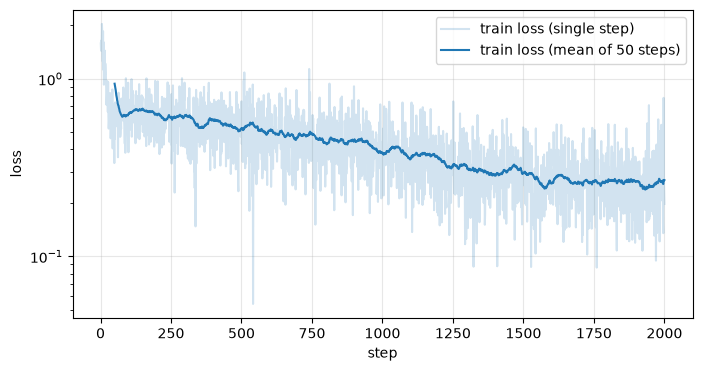

In [16]:
import matplotlib.pyplot as plt
import numpy as np

steps = np.array([r["step"] for r in log])
losses = np.array([r["loss"] for r in log])
window = min(50, len(losses))
smooth = np.convolve(losses, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(steps, losses, color="tab:blue", alpha=0.2, label="train loss (single step)")
plt.plot(steps[window - 1:], smooth, color="tab:blue", label=f"train loss (mean of {window} steps)")
plt.xlabel("step")
plt.ylabel("loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)

## Evaluation

In [17]:
import polars as pl

from glyph.markush.grading import grade

IM_END = processor.tokenizer.convert_tokens_to_ids("<|im_end|>")


@torch.no_grad()
def predict(r):
    image = Image.open(DATA_ROOT / r["images"][0]).convert("RGB")
    user_text = r["messages"][0]["content"].replace("<image>\n", "")
    inputs = processor(text=[prompt_text(user_text)], images=[image], return_tensors="pt").to(DEVICE)
    out = model.generate(**inputs, max_new_tokens=256, do_sample=False, eos_token_id=IM_END, pad_token_id=IM_END)
    return processor.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)


def evaluate(records):
    model.eval()
    rows = []
    for r in tqdm(records):
        s = grade(predict(r), r["messages"][1]["content"])["sample"]
        rows.append({"valid": s["valid_pred"], "backbone": s["backbone_inchi_match"], "exact": s["cxsmiles_full_match"]})
    return pl.DataFrame(rows).mean()


eval_records = val_records[:50]
lora_results = evaluate(eval_records)
lora_results

  0%|          | 0/50 [00:00<?, ?it/s]

valid,backbone,exact
f64,f64,f64
0.96,0.24,0.2


### vs base model

In [ ]:
lora_layers = [m for m in model.modules() if isinstance(m, LoRALinear)]
scales = [m.scale for m in lora_layers]

for m in lora_layers:
    m.scale = 0.0 # disable lora by setting scale to 0 so model uses only W matrix
base_results = evaluate(eval_records)
base_predictions = [predict(r) for r in eval_records[:3]]

for m, s in zip(lora_layers, scales):
    m.scale = s
lora_predictions = [predict(r) for r in eval_records[:3]]

pl.concat([
    base_results.with_columns(pl.lit("base model").alias("model")),
    lora_results.with_columns(pl.lit("LoRA").alias("model")),
]).select("model", "valid", "backbone", "exact")

  0%|          | 0/50 [00:00<?, ?it/s]

model,valid,backbone,exact
str,f64,f64,f64
"""base model""",0.46,0.02,0.0
"""LoRA""",0.96,0.24,0.2
